#### Configuration

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
from extensions.experiments import Sweep, generate_run, judge_run, replay_alignment

RUN = False
RUN_ALIGNMENT = False
config = Sweep(
    '02_drift_lqr_ablation', model_name='Qwen/Qwen3-4B', concept='football', trials=1000,
    lambdas=tuple(range(1, 9)), r_values=(1., 10.), last_n=(4, 8, None),
    operators=('Identity', 'Mean Jacobian', 'Random'), drift_weights=(0., 2.))
TARGETS = (0.75, 0.9)
COLORS = {0.: 'tab:blue', 2.: 'tab:orange'}
RUN_DIR = config.run_dir

#### Generate, judge, and load

In [2]:
if RUN:
    generate_run(config)
    judge_run(config)
summary = pd.read_csv(RUN_DIR / "summary.csv")
baseline = summary.loc[summary.operator.eq("Unsteered")]
steered = summary.loc[summary.operator.ne("Unsteered")]
num_layers = json.loads((RUN_DIR / "config.json").read_text())["layers"]
scopes = sorted({n or num_layers for n in config.last_n}, reverse=True)


def scope_name(N):
    return "All layers" if N == num_layers else f"Last {N} blocks"

#### Matched concept rates

In [3]:
COLUMNS = ["lambda", "coherent", "median_push_energy", "orthogonal", "along_v"]


def first_crossing(curve, target):
    curve = curve.sort_values("lambda").reset_index(drop=True)
    reached = np.flatnonzero(curve.concept.to_numpy() >= target)
    if not len(reached) or (reached[0] == 0 and curve.concept[0] != target):
        return dict.fromkeys(COLUMNS, np.nan)
    high = curve.iloc[reached[0]]
    if high.concept == target:
        return high[COLUMNS].to_dict()
    low = curve.iloc[reached[0] - 1]
    fraction = (target - low.concept) / (high.concept - low.concept)
    return (low[COLUMNS] + fraction * (high[COLUMNS] - low[COLUMNS])).to_dict()


keys = ["N", "R", "operator", "drift_weight"]
matched = pd.DataFrame(
    [
        dict(zip(keys, values), target_concept=target) | first_crossing(curve, target)
        for values, curve in steered.groupby(keys)
        for target in TARGETS
    ]
)
matched.to_csv(RUN_DIR / "matched.csv", index=False)

#### Coherence versus concept

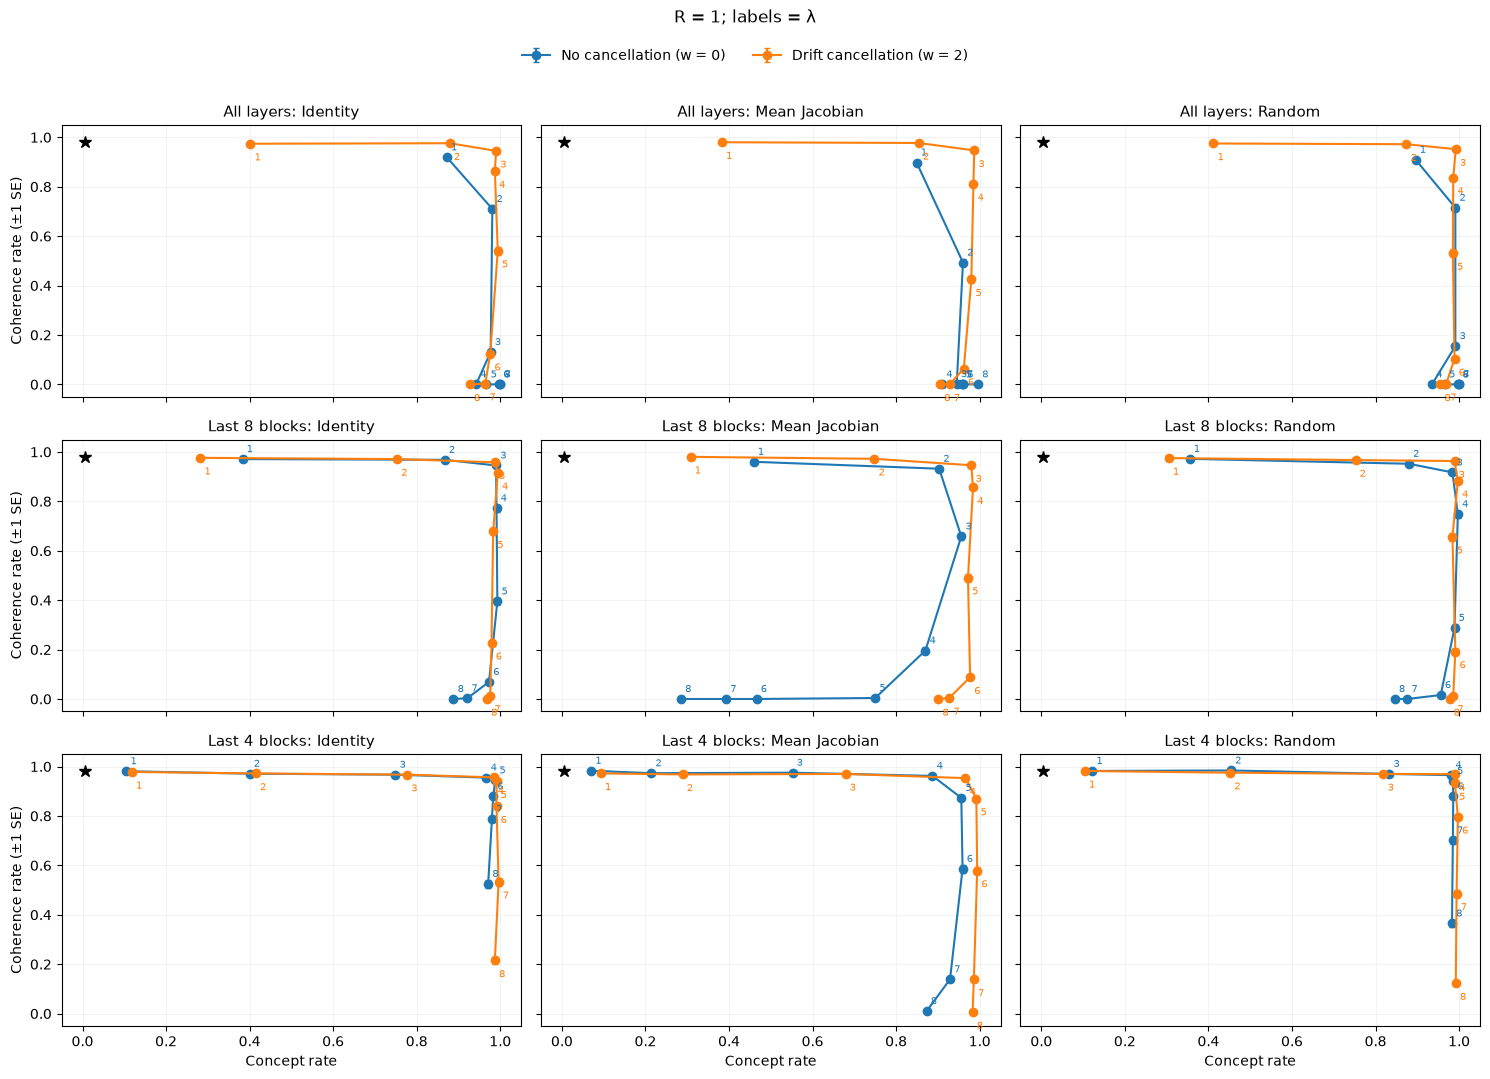

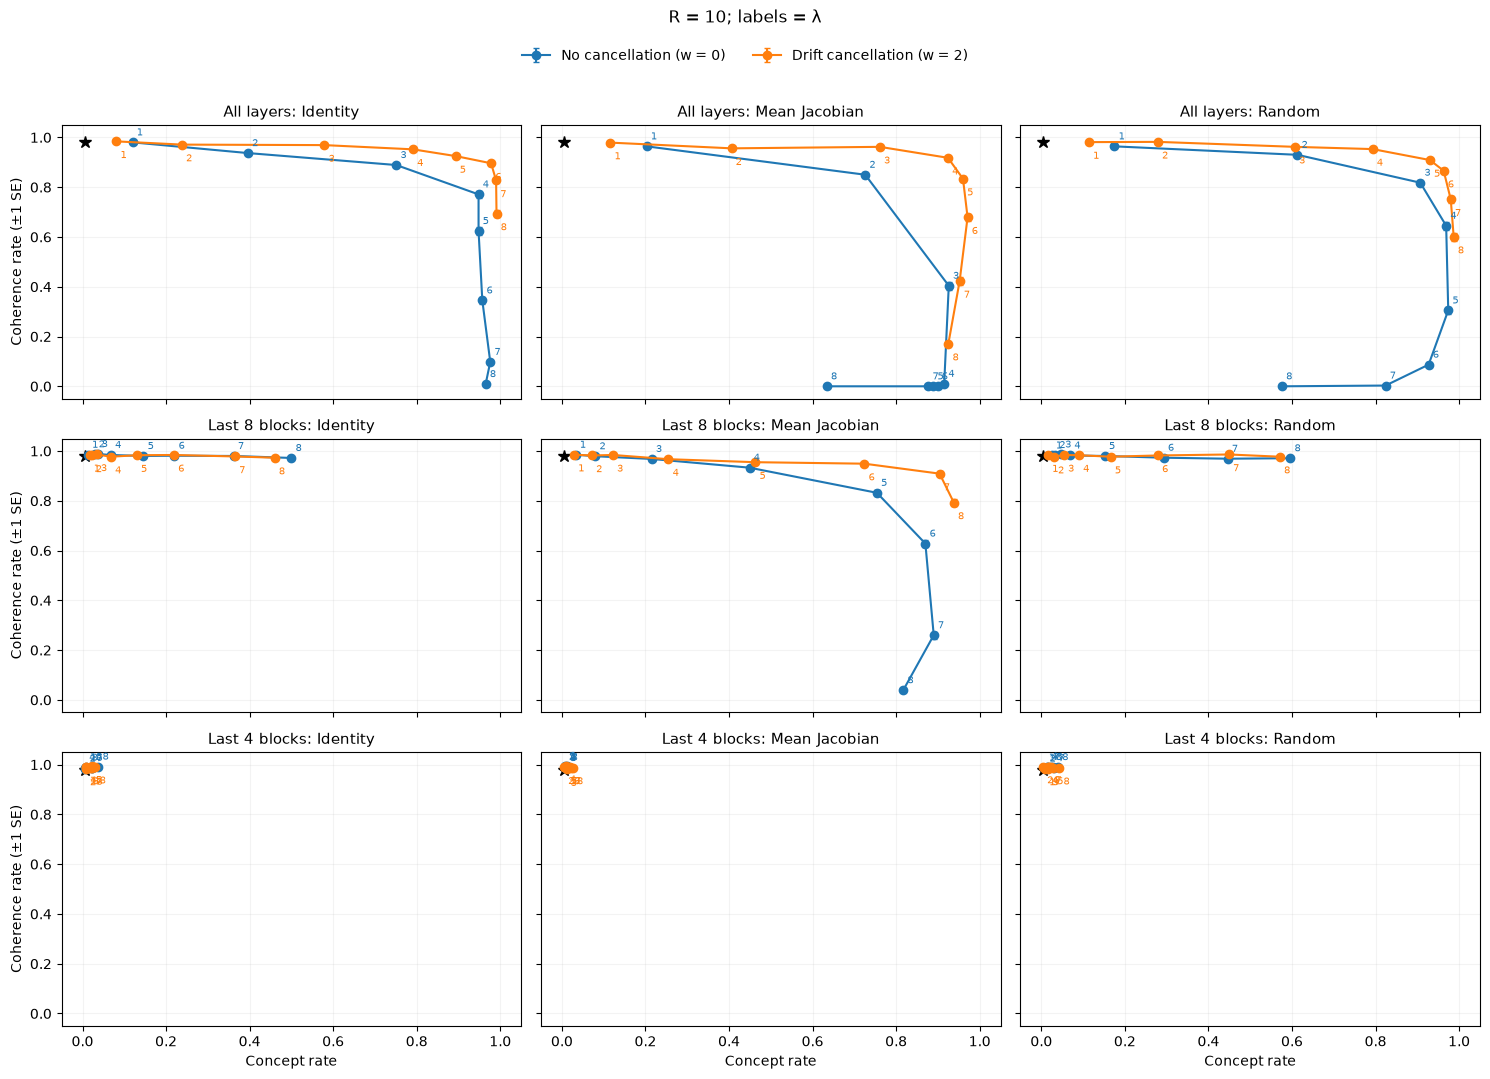

In [4]:
for R in config.r_values:
    fig, axes = plt.subplots(
        len(scopes),
        len(config.operators),
        figsize=(15, 3.6 * len(scopes)),
        sharex=True,
        sharey=True,
    )
    for row, N in zip(axes, scopes):
        for ax, name in zip(row, config.operators):
            panel = steered.loc[
                steered.R.eq(R) & steered.N.eq(N) & steered.operator.eq(name)
            ]
            for weight, curve in panel.groupby("drift_weight"):
                curve = curve.sort_values("lambda")
                ax.errorbar(
                    curve.concept,
                    curve.coherent,
                    yerr=curve.coherent_se,
                    marker="o",
                    capsize=2,
                    color=COLORS[weight],
                    label=f"{'No' if weight == 0 else 'Drift'} cancellation (w = {weight:g})",
                )
                for x, y, strength in zip(
                    curve.concept, curve.coherent, curve["lambda"]
                ):
                    ax.annotate(
                        f"{strength:g}",
                        (x, y),
                        fontsize=7,
                        color=COLORS[weight],
                        xytext=(3, 5 if weight == 0 else -12),
                        textcoords="offset points",
                    )
            ax.plot(baseline.concept, baseline.coherent, "k*", ms=9)
            ax.set_title(f"{scope_name(N)}: {name}", fontsize=11)
            ax.grid(alpha=0.15)
    for ax in axes[-1]:
        ax.set_xlabel("Concept rate")
    for ax in axes[:, 0]:
        ax.set_ylabel("Coherence rate (±1 SE)")
    axes[0, 0].set(xlim=(-0.05, 1.05), ylim=(-0.05, 1.05))
    fig.legend(
        *axes[0, 0].get_legend_handles_labels(),
        loc="upper center",
        bbox_to_anchor=(0.5, 0.97),
        ncol=2,
        frameon=False,
    )
    fig.suptitle(f"R = {R:g}; labels = λ", y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(RUN_DIR / f"concept_coherence_r{R:g}.png", dpi=150)
    plt.show()

#### Where does the change go?

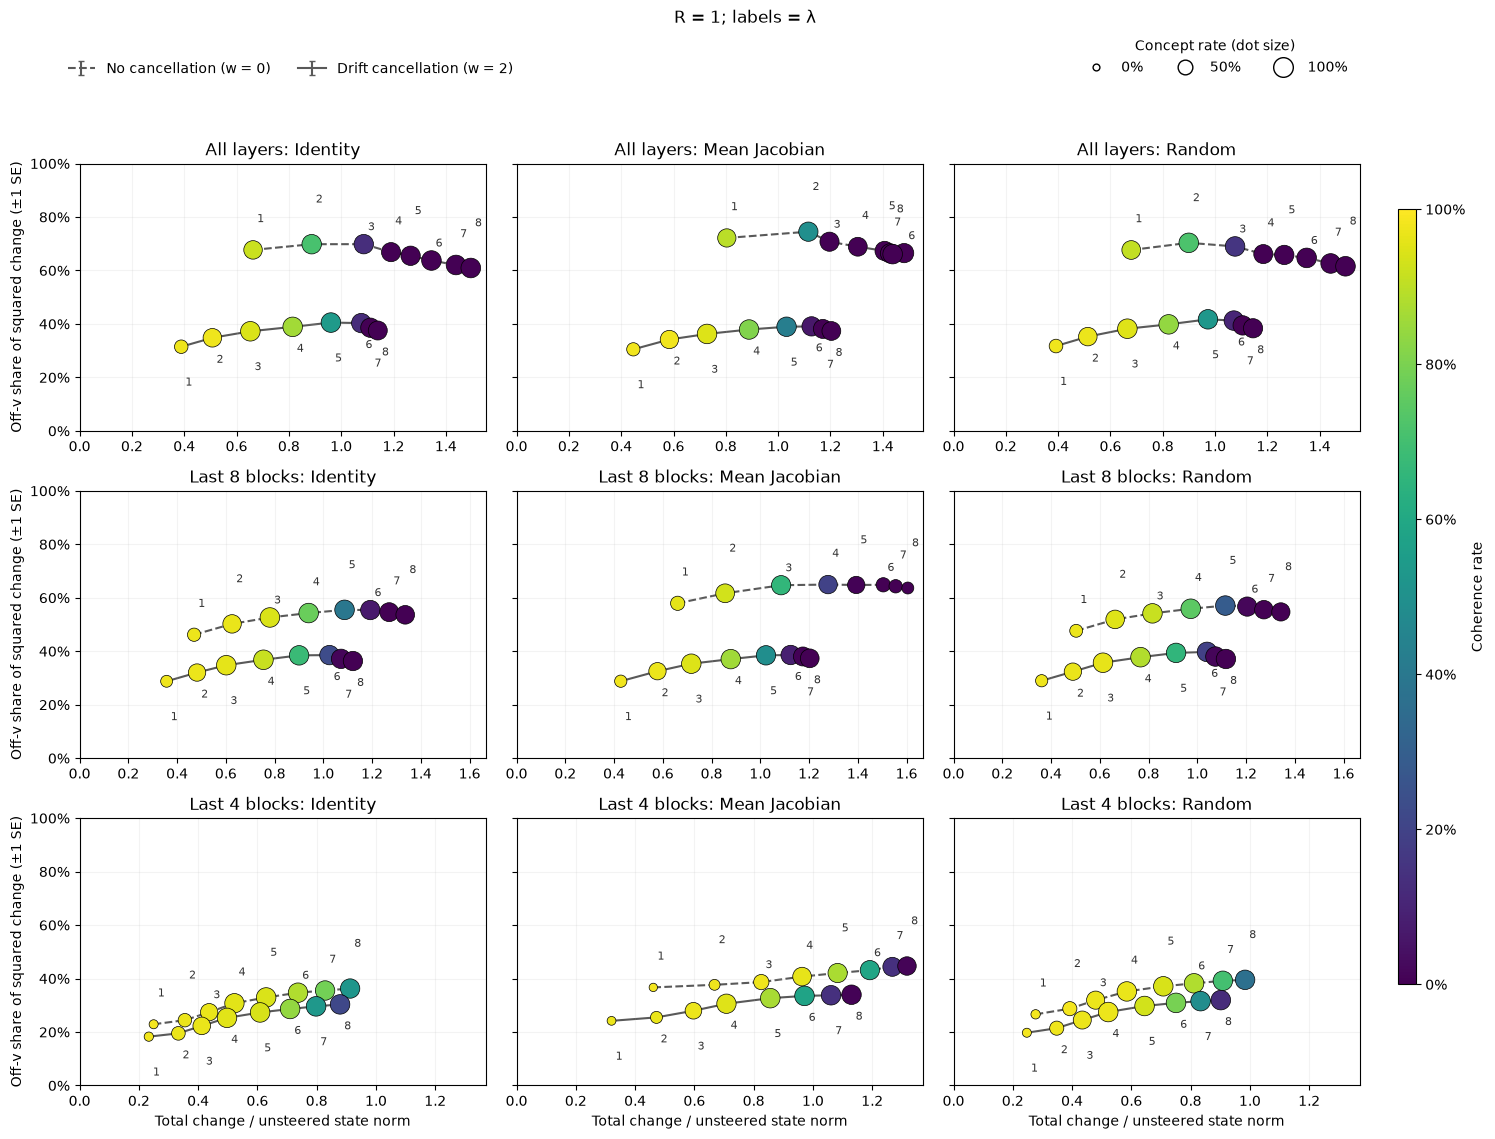

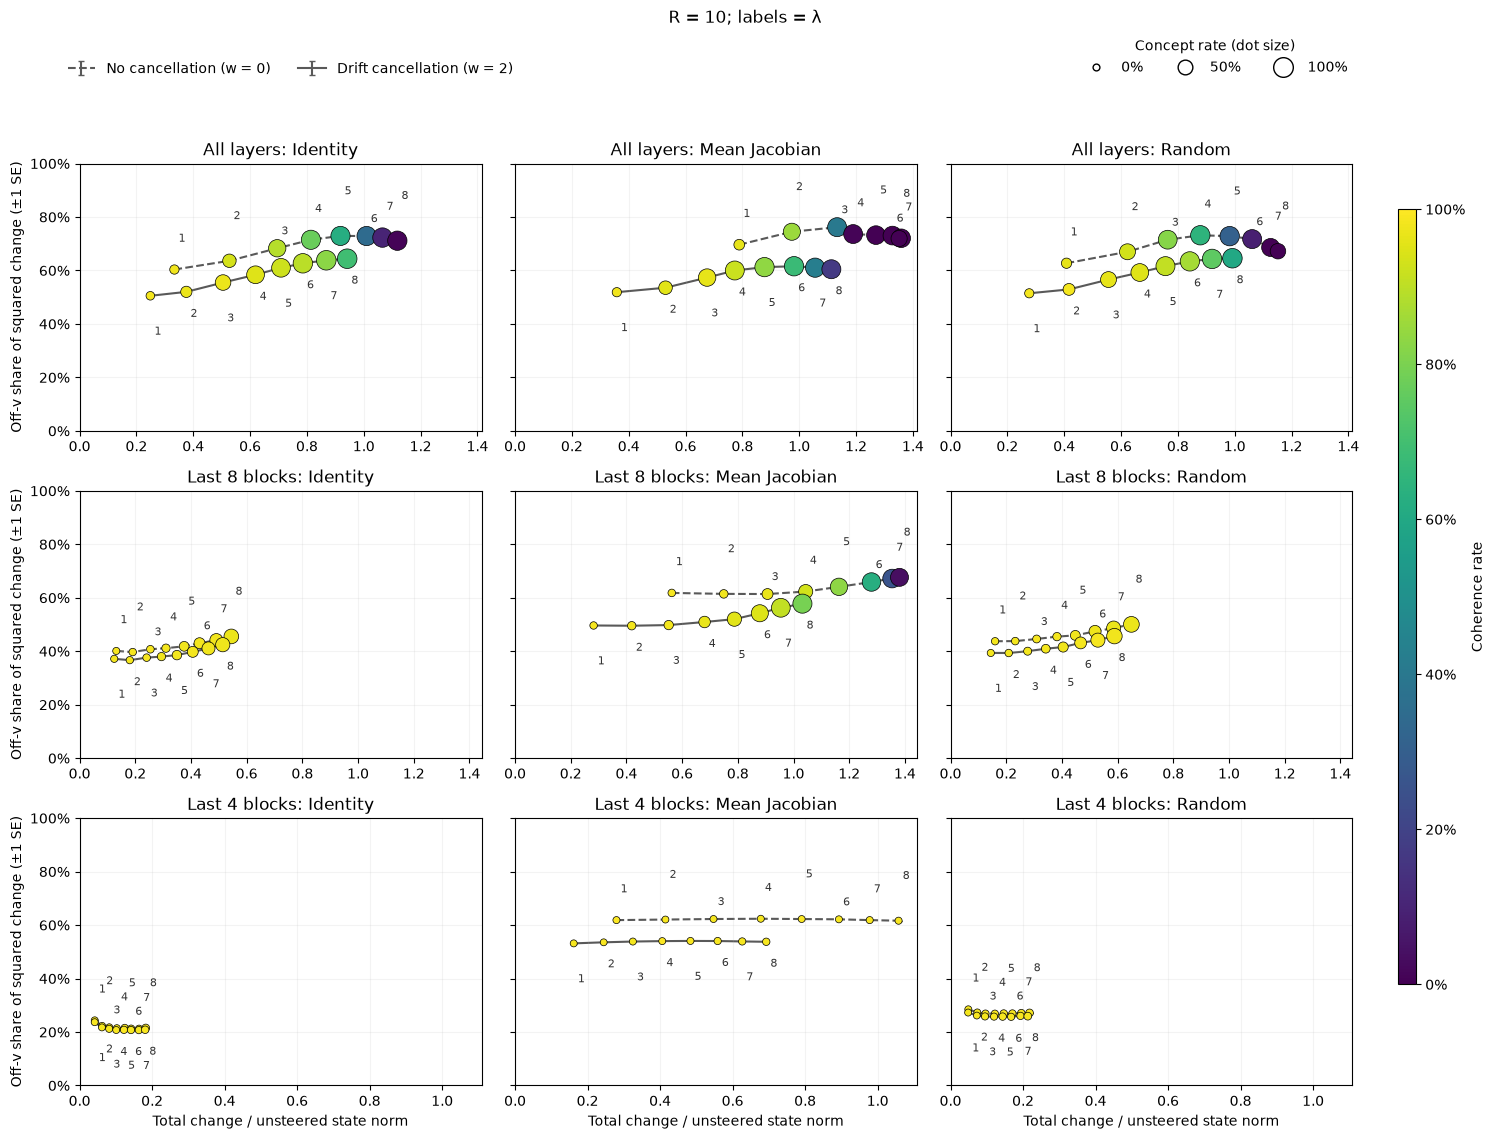

In [5]:
if RUN_ALIGNMENT:
    replay_alignment(config)
alignment_dir = RUN_DIR / "alignment"
alignment = pd.read_csv(alignment_dir / "summary.csv")
for R in config.r_values:
    fig, axes = plt.subplots(
        len(scopes),
        len(config.operators),
        figsize=(15, 3.8 * len(scopes)),
        sharex="row",
        sharey=True,
    )
    for row, N in zip(axes, scopes):
        for ax, name in zip(row, config.operators):
            panel = alignment.loc[
                alignment.R.eq(R) & alignment.N.eq(N) & alignment.operator.eq(name)
            ]
            for weight, curve in panel.groupby("drift_weight"):
                curve = curve.sort_values("lambda")
                ax.errorbar(
                    curve.change,
                    curve.off_fraction,
                    yerr=curve.off_fraction_se,
                    capsize=2,
                    color="0.35",
                    linestyle="--" if weight == 0 else "-",
                    zorder=1,
                    label=f"{'No' if weight == 0 else 'Drift'} cancellation (w = {weight:g})",
                )
                points = ax.scatter(
                    curve.change,
                    curve.off_fraction,
                    c=curve.coherent,
                    s=24 + 176 * curve.concept,
                    cmap="viridis",
                    vmin=0,
                    vmax=1,
                    edgecolors="black",
                    linewidths=0.5,
                    zorder=3,
                )
                for x, y, strength in zip(
                    curve.change, curve.off_fraction, curve["lambda"]
                ):
                    offset = (
                        10 + 10 * (strength % 3)
                        if weight == 0
                        else -18 - 10 * (strength % 2)
                    )
                    ax.annotate(
                        f"{strength:g}",
                        (x, y),
                        fontsize=8,
                        color="0.2",
                        xytext=(3, offset),
                        textcoords="offset points",
                    )
            ax.set(title=f"{scope_name(N)}: {name}", ylim=(0, 1))
            ax.yaxis.set_major_formatter(PercentFormatter(1))
            ax.grid(alpha=0.15)
        row[0].set_xlim(left=0)
        row[0].set_ylabel("Off-v share of squared change (±1 SE)")
    for ax in axes[-1]:
        ax.set_xlabel("Total change / unsteered state norm")
    fig.legend(
        *axes[0, 0].get_legend_handles_labels(),
        loc="upper left",
        bbox_to_anchor=(0.04, 0.96),
        ncol=2,
        frameon=False,
    )
    sizes = [
        Line2D(
            [],
            [],
            linestyle="",
            marker="o",
            markerfacecolor="white",
            markeredgecolor="black",
            markersize=(24 + 176 * rate) ** 0.5,
            label=f"{rate:.0%}",
        )
        for rate in (0.0, 0.5, 1.0)
    ]
    fig.legend(
        handles=sizes,
        title="Concept rate (dot size)",
        loc="upper right",
        bbox_to_anchor=(0.91, 0.98),
        ncol=3,
        frameon=False,
    )
    fig.suptitle(f"R = {R:g}; labels = λ", y=0.995)
    fig.tight_layout(rect=(0, 0, 0.92, 0.92))
    fig.colorbar(
        points, cax=fig.add_axes([0.935, 0.14, 0.012, 0.68]), format=PercentFormatter(1)
    ).set_label("Coherence rate")
    fig.savefig(alignment_dir / f"alignment_r{R:g}.png", dpi=150)
    plt.show()